# The hand-swap bug: measuring train-serve skew in MediaPipe sign recognition

Live app: [https://swapnil007-curious.github.io/ManuVox/](https://swapnil007-curious.github.io/ManuVox/) · GitHub: [https://github.com/Swapnil007-Curious/ManuVox](https://github.com/Swapnil007-Curious/ManuVox) · Paper: link coming soon

A sign classifier can lose most of its accuracy in a live app while the model file stays the same, because the live pipeline feeds it slightly different numbers than training did. ManuVox hit this: its first browser build put each detected hand in the other hand's slot. On the author's 50 webcam clips, fixing that one mapping raised clip top-1 from 10% to 46% in the Python pipeline and from 16% to 41% in the browser (`results/live_gap_v2.md` in the repository). This notebook trains the model from notebook 4 on a shorter schedule, then replays six skews on four held-out signers: swapped hand slots, a mirrored camera, flipped coordinates, other camera aspect ratios, lower frame rates and dropped frames. It measures the accuracy each one costs and tests a fix for two of them.

Data: the `asl-signs` competition files only (CC BY 4.0). Needs a GPU (T4), about 30 minutes on Kaggle. Part 2 of a 5-notebook series.

Contents

1. Setup and data
2. Train on clean data
3. The skews as functions
4. What each skew costs
5. Fixing the hand slots
6. Aspect ratio: a sweep and a self-calibrating fix
7. Frame rate and dropped frames
8. What we found

## 1. Setup and data

The readers and the preprocessing are the same as in notebook 1. Preprocessing drops frames without a hand, mirrors left-dominant sequences, centres on the shoulders, divides by the shoulder width and resamples 32 frames.

In [1]:
import json
import math
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from cycler import cycler
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Kaggle paths. The environment variables only matter when the notebook runs outside Kaggle.
INPUT_DIR = Path(os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input"))
WORK_DIR = Path(os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
# FAST=1 keeps a few sequences per sign, for testing the notebook end to end on a laptop.
FAST = os.environ.get("MANUVOX_FAST", "0") == "1"
FAST_PER_SIGN = 24  # Sequences per sign in FAST mode (250 signs, so about 6,000 sequences).
SEED = 42  # One seed for every random choice in the notebook.
N_WORKERS = os.cpu_count() or 1  # Kaggle gives 4 CPUs.

random.seed(SEED)
np.random.seed(SEED)

# Plot style: a colour-blind-safe categorical palette (checked for deutan, protan and tritan
# separation), one blue ramp for magnitudes, hairline grids.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=PALETTE),
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "legend.frameon": False,
        "figure.dpi": 100,
        "font.size": 10,
    }
)


def takeaway(text):
    """Print the one-line reading of the plot above, written from this run's numbers."""
    display(Markdown(f"Takeaway: {text}"))


def save_cover(fig, name="cover.png"):
    """Save a 1280x720 copy of ``fig`` as the notebook's cover image."""
    fig.set_size_inches(12.8, 7.2)
    fig.savefig(WORK_DIR / name, dpi=100)


print(f"FAST mode: {FAST}; {N_WORKERS} CPUs")
if FAST:
    print(f"FAST is a test run on up to {FAST_PER_SIGN} sequences per sign with short training: "
          "every number below comes from that sample, not from the full data.")

FAST mode: True; 4 CPUs
FAST is a test run on up to 24 sequences per sign with short training: every number below comes from that sample, not from the full data.


In [2]:
import multiprocessing as mp

COMPETITION = "asl-signs"
# Every frame of a sequence file holds 543 rows in this order (checked on a sample below).
BLOCKS = {"face": 468, "left_hand": 21, "pose": 33, "right_hand": 21}
ROWS_PER_FRAME = sum(BLOCKS.values())
LEFT_START, POSE_START, RIGHT_START = 468, 489, 522
# Selected landmarks: left hand 0-20, right hand 0-20, then pose 0-16 (nose, eyes, ears, mouth
# corners, shoulders, elbows, wrists). The face mesh is dropped. L = 59.
POSE_POINTS = list(range(17))
SELECTED = np.r_[
    LEFT_START : LEFT_START + 21, RIGHT_START : RIGHT_START + 21, POSE_START + np.array(POSE_POINTS)
]
N_LANDMARKS = len(SELECTED)
LEFT, RIGHT = slice(0, 21), slice(21, 42)
NOSE, L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = (42 + i for i in (0, 11, 12, 15, 16))
# Left/right pose pairs that a mirror swaps (eyes, ears, mouth corners, shoulders, elbows, wrists).
POSE_SWAP_PAIRS = [(1, 4), (2, 5), (3, 6), (7, 8), (9, 10), (11, 12), (13, 14), (15, 16)]
NUM_FRAMES = 32  # Every sequence is resampled to this many frames.
MIN_HAND_FRAMES = 3  # Sequences with fewer frames showing a hand are dropped.
FRAME_DIM = 2 * N_LANDMARKS + 2  # x, y per landmark, then left and right hand presence.


def find_competition_dir(root=INPUT_DIR, name=COMPETITION):
    """Return the folder holding train.csv and the sign map, wherever Kaggle mounts it."""
    for candidate in (root / name, root / "competitions" / name):
        if (candidate / "train.csv").is_file():
            return candidate
    for folder, subfolders, files in os.walk(root, followlinks=True):
        subfolders[:] = [s for s in subfolders if s != "train_landmark_files"]
        if "train.csv" in files and "sign_to_prediction_index_map.json" in files:
            return Path(folder)
    raise FileNotFoundError("Add the competition data: Add Input > Competitions > asl-signs")


def load_table(data_dir, fast=FAST):
    """train.csv with integer labels; in FAST mode, up to FAST_PER_SIGN files per sign on disk."""
    table = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
    sign_map = json.loads((data_dir / "sign_to_prediction_index_map.json").read_text())
    table["label"] = table["sign"].map(sign_map).astype(int)
    if fast:
        on_disk = table["path"].map(lambda p: (data_dir / p).is_file())
        table = table[on_disk].groupby("sign", sort=False).head(FAST_PER_SIGN)
    return table.reset_index(drop=True), sign_map


def check_layout(paths):
    """Confirm each file stores whole frames of 543 rows in the fixed block order."""
    types = np.repeat(list(BLOCKS), list(BLOCKS.values()))
    index = np.concatenate([np.arange(n) for n in BLOCKS.values()])
    for path in paths:
        df = pd.read_parquet(path, columns=["frame", "type", "landmark_index"])
        frames = len(df) // ROWS_PER_FRAME
        assert len(df) == frames * ROWS_PER_FRAME, f"{path.name}: partial frame"
        frame_ids = df["frame"].to_numpy().reshape(frames, ROWS_PER_FRAME)
        assert (frame_ids == frame_ids[:, :1]).all(), f"{path.name}: frames interleaved"
        assert (np.diff(frame_ids[:, 0]) > 0).all(), f"{path.name}: frames out of order"
        assert (df["type"].to_numpy().reshape(frames, -1) == types).all(), f"{path.name}: types"
        assert (df["landmark_index"].to_numpy().reshape(frames, -1) == index).all()
    return len(paths)


def read_frames(path, columns=("x", "y")):
    """All 543 landmarks of one file as a (frames, 543, len(columns)) float32 array, NaN = missing."""
    table = pq.read_table(path, columns=list(columns))
    values = [table.column(c).to_numpy().astype(np.float32) for c in columns]
    return np.stack(values, axis=-1).reshape(-1, ROWS_PER_FRAME, len(columns))


def read_xy(path):
    """The 59 selected landmarks of one file, (frames, 59, 2): x and y as fractions of the frame."""
    return read_frames(path)[:, SELECTED]


# Worker processes are forked (Linux, as on Kaggle); elsewhere the work runs in this process.
WORKERS_USED = N_WORKERS if N_WORKERS > 1 and "fork" in mp.get_all_start_methods() else 1


def parallel_map(function, items, chunksize=32):
    """Map over items with one forked process per CPU (Linux, as on Kaggle), else in a loop."""
    if WORKERS_USED > 1:
        with mp.get_context("fork").Pool(N_WORKERS) as pool:
            return list(pool.imap(function, items, chunksize=chunksize))
    return [function(item) for item in items]

In [3]:
def hand_presence(xy):
    """(frames, 2) booleans: is the left / right hand present (all 21 points finite)?"""
    finite = np.isfinite(xy).all(axis=-1)
    return np.stack([finite[:, LEFT].all(axis=1), finite[:, RIGHT].all(axis=1)], axis=1)


def mirror_permutation():
    """Landmark order after a mirror: hands swap blocks and each left/right pose pair swaps."""
    order = np.arange(N_LANDMARKS)
    order[LEFT], order[RIGHT] = np.arange(21, 42), np.arange(21)
    for a, b in POSE_SWAP_PAIRS:
        order[[42 + a, 42 + b]] = [42 + b, 42 + a]
    return order


MIRROR = mirror_permutation()


def mirror(xy):
    """Mirror a sequence: x -> 1 - x and every left/right landmark pair trades places."""
    out = xy[:, MIRROR].copy()
    out[..., 0] = 1.0 - out[..., 0]
    return out


def normalisation(xy):
    """(centre, scale): median shoulder midpoint and shoulder width; the hands if no shoulders."""
    left, right = xy[:, L_SHOULDER], xy[:, R_SHOULDER]
    both = np.isfinite(left).all(axis=1) & np.isfinite(right).all(axis=1)
    if both.any():
        centre = np.nanmedian(0.5 * (left + right), axis=0)
        width = np.hypot(left[:, 0] - right[:, 0], left[:, 1] - right[:, 1])
        return centre, float(np.nanmedian(width))
    hands = xy[:, :42].reshape(-1, 2)
    spread = np.nanmax(hands, axis=0) - np.nanmin(hands, axis=0)
    return np.nanmean(hands, axis=0), float(spread.max())


def resample(xy, num_frames=NUM_FRAMES):
    """Linear resampling over the frame index, between finite values of each coordinate only."""
    t = len(xy)
    flat = xy.reshape(t, -1).astype(np.float64)
    position = np.linspace(0.0, t - 1, num_frames)
    out = np.full((num_frames, flat.shape[1]), np.nan)
    finite = np.isfinite(flat)
    full = finite.all(axis=0)  # Columns without gaps: one vectorised interpolation.
    low = np.floor(position).astype(int)
    high = np.minimum(low + 1, t - 1)
    weight = (position - low)[:, None]
    out[:, full] = flat[low][:, full] * (1.0 - weight) + flat[high][:, full] * weight
    source = np.arange(t)
    for column in np.flatnonzero(~full & finite.any(axis=0)):
        ok = finite[:, column]
        out[:, column] = np.interp(
            position, source[ok], flat[ok, column], left=np.nan, right=np.nan
        )
    return out.reshape(num_frames, *xy.shape[1:])


def preprocess(xy):
    """Raw (frames, 59, 2) landmarks -> ((32, 120) float32 model input, info), or (None, info).

    Frames without a hand are dropped; a left-dominant sequence is mirrored so the dominant
    hand is always in the right-hand block; coordinates are centred on the shoulders and divided
    by the shoulder width; then 32 frames are resampled and missing points become 0.0.
    """
    info = {"t_raw": len(xy), "t_kept": 0, "mirrored": False}
    present = hand_presence(xy)
    keep = present.any(axis=1)
    xy, present = xy[keep], present[keep]
    info["t_kept"] = len(xy)
    if len(xy) < MIN_HAND_FRAMES:
        return None, info
    if present[:, 0].sum() > present[:, 1].sum():  # Left hand seen in more frames: mirror.
        xy, present = mirror(xy), present[:, ::-1]
        info["mirrored"] = True
    centre, scale = normalisation(xy)
    if not np.isfinite(scale) or scale < 1e-6:
        return None, info
    coords = resample((xy - centre) / scale)
    nearest = np.floor(np.linspace(0.0, len(xy) - 1, NUM_FRAMES) + 0.5).astype(int)
    frames = np.concatenate(
        [np.nan_to_num(coords, nan=0.0).reshape(NUM_FRAMES, -1), present[nearest]], axis=1
    )
    return frames.astype(np.float32), info


def _load_one(path):
    features, info = preprocess(read_xy(path))
    return (None if features is None else features.astype(np.float16)), info


def build_features(table, data_dir):
    """Preprocess every row of ``table``: returns (X float16 (n, 32, 120), kept rows, info)."""
    started = time.perf_counter()
    results = parallel_map(_load_one, [data_dir / p for p in table["path"]])
    info = pd.DataFrame([r[1] for r in results])
    kept = np.array([r[0] is not None for r in results])
    X = np.stack([r[0] for r in results if r[0] is not None])
    rows = table[kept].reset_index(drop=True)
    print(
        f"preprocessed {len(table):,} sequences in {time.perf_counter() - started:.0f} s: "
        f"{kept.sum():,} kept, {(~kept).sum():,} dropped (fewer than {MIN_HAND_FRAMES} hand frames)"
    )
    return X, rows, info.assign(kept=kept)


def signer_split(rows, n_test=4, n_val=3, seed=SEED):
    """Assign whole participants to test, val and train (the repository's seed-42 split)."""
    participants = np.random.default_rng(seed).permutation(np.unique(rows["participant_id"]))
    test, val = participants[:n_test], participants[n_test : n_test + n_val]
    split = np.where(
        rows["participant_id"].isin(test), "test", np.where(rows["participant_id"].isin(val), "val", "train")
    )
    return split, sorted(test.tolist()), sorted(val.tolist())

In [4]:
import torch
from torch import nn
from torch.nn import functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # A T4 on Kaggle; CPU works for FAST runs.
EPOCHS = 4 if FAST else 30  # Notebook 4 trains 80 epochs; 30 is enough to study the skews.
EMA_DECAY = 0.99 if FAST else 0.999  # Weight averaging; FAST runs too few steps for 0.999.

The model, augmentation and training code is identical to notebook 4 and is collapsed here. Expand the next cell to read it.

In [5]:
import itertools

import torch
from torch import nn
from torch.nn import functional as F

HAND_PAIRS = list(itertools.combinations(range(21), 2))  # 210 point pairs of one hand.
FINGER_POINTS = (0, 4, 8, 12, 16, 20)  # Wrist and the five fingertips.
COORDS = 2 * N_LANDMARKS  # 118 coordinates per frame.


class FeatureBlock(nn.Module):
    """(B, 32, 120) frames -> (B, 32, 588) standardised features, inside the model.

    Features: coordinates, velocity and acceleration of all 59 points, the 210 pairwise distances
    of the dominant (right-block) hand, and 24 distances from its wrist and fingertips to the
    nose, mouth centre and shoulders. A point is missing when x == y == 0, and anything derived
    from a missing point is 0. Living inside the model means the ONNX export carries it too.
    """

    def __init__(self):
        super().__init__()
        self.output_dim = 3 * COORDS + len(HAND_PAIRS) + len(FINGER_POINTS) * 4
        first, second = zip(*HAND_PAIRS)
        self.register_buffer("pair_a", torch.tensor(first) + 21, persistent=False)
        self.register_buffer("pair_b", torch.tensor(second) + 21, persistent=False)
        self.register_buffer("fingers", torch.tensor(FINGER_POINTS) + 21, persistent=False)
        face = [NOSE, 42 + 9, 42 + 10, L_SHOULDER, R_SHOULDER]  # Nose, mouth corners, shoulders.
        self.register_buffer("targets", torch.tensor(face), persistent=False)
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        second = (p[:, 2:] - 2 * p[:, 1:-1] + p[:, :-2]) * (ok[:, 2:] * ok[:, 1:-1] * ok[:, :-2]).unsqueeze(-1)
        acceleration = torch.cat([torch.zeros_like(second[:, :2]), second], dim=1)
        shape = distances(
            p.index_select(2, self.pair_a),
            p.index_select(2, self.pair_b),
            ok.index_select(2, self.pair_a) * ok.index_select(2, self.pair_b),
        )
        tg, tg_ok = p.index_select(2, self.targets), ok.index_select(2, self.targets)
        mouth = 0.5 * (tg[:, :, 1:2] + tg[:, :, 2:3])
        anchors = torch.cat([tg[:, :, :1], mouth, tg[:, :, 3:]], dim=2)
        anchors_ok = torch.cat([tg_ok[:, :, :1], tg_ok[:, :, 1:2] * tg_ok[:, :, 2:3], tg_ok[:, :, 3:]], dim=2)
        hand, hand_ok = p.index_select(2, self.fingers), ok.index_select(2, self.fingers)
        to_body = distances(
            hand.unsqueeze(3), anchors.unsqueeze(2), hand_ok.unsqueeze(3) * anchors_ok.unsqueeze(2)
        )
        return torch.cat(
            [
                x[..., :COORDS],
                velocity.reshape(b, t, COORDS),
                acceleration.reshape(b, t, COORDS),
                shape,
                to_body.reshape(b, t, -1),
            ],
            dim=-1,
        )

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


class SimpleFeatures(nn.Module):
    """Coordinates and velocity only, (B, 32, 236): the cheaper input of the temporal CNN."""

    def __init__(self):
        super().__init__()
        self.output_dim = 2 * COORDS
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        return torch.cat([x[..., :COORDS], velocity.reshape(b, t, COORDS)], dim=-1)

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


def distances(a, b, valid):
    """Euclidean distance over the last axis, 0 where ``valid`` is 0."""
    return torch.sqrt(((a - b) ** 2).sum(dim=-1)) * valid


@torch.no_grad()
def fit_standardisation(block, x_train, chunk=4096):
    """Set the block's mean and std from every frame of the train split (float64 sums)."""
    total = torch.zeros(block.output_dim, dtype=torch.float64, device=x_train.device)
    squares = torch.zeros_like(total)
    for start in range(0, len(x_train), chunk):
        values = block.raw(x_train[start : start + chunk].float()).reshape(-1, block.output_dim).double()
        total += values.sum(dim=0)
        squares += (values**2).sum(dim=0)
    count = x_train.shape[0] * x_train.shape[1]
    mean = total / count
    block.mean.copy_(mean)
    block.std.copy_((squares / count - mean**2).clamp_min(0).sqrt().clamp_min(1e-6))

In [6]:
class SelfAttention(nn.Module):
    """Multi-head self-attention written with Linear and MatMul, which export and quantise cleanly."""

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.heads, self.head_dim = heads, dim // heads
        self.query, self.key, self.value, self.out = (nn.Linear(dim, dim) for _ in range(4))
        self.dropout = nn.Dropout(dropout)

    def split(self, x):
        return x.reshape(-1, x.shape[1], self.heads, self.head_dim).transpose(1, 2)

    def forward(self, x):
        q = self.split(self.query(x)) * self.head_dim**-0.5
        weights = torch.softmax(q @ self.split(self.key(x)).transpose(-2, -1), dim=-1)
        context = self.dropout(weights) @ self.split(self.value(x))
        return self.out(context.transpose(1, 2).flatten(2))


class TransformerBlock(nn.Module):
    """Pre-norm transformer encoder block."""

    def __init__(self, dim, heads=4, ff_dim=512, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attention = SelfAttention(dim, heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.ff =nn.Sequential(nn.Linear(dim, ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim, dim))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.dropout(self.attention(self.norm1(x)))
        return x + self.dropout(self.ff(self.norm2(x)))


class ConvBlock(nn.Module):
    """Depthwise temporal conv -> BatchNorm -> SiLU -> expand -> SiLU -> project, residual. (B, C, T)."""

    def __init__(self, dim, kernel=17, expansion=512, dropout=0.2):
        super().__init__()
        self.depthwise = nn.Conv1d(dim, dim, kernel, padding=kernel // 2, groups=dim)
        self.norm = nn.BatchNorm1d(dim)
        self.expand, self.project = nn.Conv1d(dim, expansion, 1), nn.Conv1d(expansion, dim, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        h = F.silu(self.norm(self.depthwise(x)))
        return x + self.dropout(self.project(F.silu(self.expand(h))))


class Stage(nn.Module):
    """Two conv blocks over time, then one transformer block. (B, T, C)."""

    def __init__(self, dim):
        super().__init__()
        self.convs = nn.Sequential(ConvBlock(dim), ConvBlock(dim))
        self.transformer = TransformerBlock(dim)

    def forward(self, x):
        return self.transformer(self.convs(x.transpose(1, 2)).transpose(1, 2))


class HybridClassifier(nn.Module):
    """Features -> linear projection -> 3 conv+transformer stages -> mean over time -> head.

    Head dropout switches on halfway through training ("late dropout").
    """

    def __init__(self, num_classes=250, dim=256, stages=3, head_dropout=0.4):
        super().__init__()
        self.features = FeatureBlock()
        self.proj = nn.Linear(self.features.output_dim, dim)
        self.stages = nn.Sequential(*(Stage(dim) for _ in range(stages)))
        self.head_dropout, self.late_dropout_on = head_dropout, False
        self.head = nn.Linear(dim, num_classes)

    def set_progress(self, epoch, epochs):
        """Called before each 1-based epoch: head dropout is on for the second half."""
        self.late_dropout_on = (epoch - 1) >= 0.5 * epochs

    def forward(self, x):
        h = self.stages(self.proj(self.features(x))).mean(dim=1)
        if self.training and self.late_dropout_on:
            h = F.dropout(h, self.head_dropout)
        return self.head(h)

In [7]:
# Per-sample probabilities. RECIPE_V2 is the repository's v2 recipe; RECIPE_V1 only the first three.
RECIPE_V1 = {"affine": 0.8, "temporal_crop": 0.5, "jitter": 0.5}
RECIPE_V2 = {**RECIPE_V1, "hand_rotation": 0.5, "frame_dropout": 0.5, "time_mask": 0.5, "landmark_mask": 0.3}


def _chosen(p, batch, gen, like):
    """Bernoulli(p) per sample, shape (B,)."""
    return torch.rand(batch, generator=gen, device=like.device) < p


def _uniform(shape, low, high, gen, like):
    return low + (high - low) * torch.rand(shape, generator=gen, device=like.device, dtype=like.dtype)


def _take_frames(values, index):
    """values[b, index[b, t]] for (B, T, ...) values and a (B, T) frame index."""
    shaped = index.reshape(*index.shape, *([1] * (values.dim() - 2)))
    return values.gather(1, shaped.expand(-1, -1, *values.shape[2:]))


def _blend(points, presence, missing, low, high, weight, nearest):
    """Linear blend of frames ``low`` and ``high``; a blend touching a missing point is missing."""
    start, end = _take_frames(points, low), _take_frames(points, high)
    gone = _take_frames(missing, low) | _take_frames(missing, high)
    blended = (start + (end - start) * weight[..., None, None]).masked_fill(gone[..., None], 0.0)
    return blended, _take_frames(presence, nearest), gone


def affine(points, missing, gen, rotate=15.0, scale=(0.85, 1.15), shift=0.1):
    """Rotate, scale and translate the whole skeleton."""
    b = points.shape[0]
    angle = _uniform((b,), -rotate, rotate, gen, points) * math.pi / 180
    size = _uniform((b,), *scale, gen, points)
    move = _uniform((b, 2), -shift, shift, gen, points)
    cos, sin = torch.cos(angle) * size, torch.sin(angle) * size
    matrix = torch.stack([torch.stack([cos, sin], -1), torch.stack([-sin, cos], -1)], -2)
    out = torch.einsum("btlc,bcd->btld", points, matrix) + move[:, None, None]
    return out.masked_fill(missing[..., None], 0.0)


def hand_rotation(points, missing, gen, degrees=10.0):
    """Rotate each hand about its own wrist by its own angle."""
    out = points.clone()
    angle = _uniform((points.shape[0], 2), -degrees, degrees, gen, points) * math.pi / 180
    for h, block in enumerate((LEFT, RIGHT)):
        cos, sin = torch.cos(angle[:, h])[:, None, None], torch.sin(angle[:, h])[:, None, None]
        hand = points[:, :, block]
        offset = hand - hand[:, :, :1]
        turned = hand[:, :, :1] + torch.stack(
            [offset[..., 0] * cos - offset[..., 1] * sin, offset[..., 0] * sin + offset[..., 1] * cos], -1
        )
        ok = ~missing[:, :, block] & ~missing[:, :, block][:, :, :1]
        out[:, :, block] = torch.where(ok[..., None], turned, hand)
    return out


def temporal_crop(points, presence, missing, gen, window_min=0.8):
    """Keep a random window of 80-100% of the sequence and stretch it back to 32 frames."""
    b, t = points.shape[:2]
    last = t - 1
    length = _uniform((b,), window_min, 1.0, gen, points) * last
    offset = _uniform((b,), 0.0, 1.0, gen, points) * (last - length)
    steps = torch.arange(t, device=points.device, dtype=points.dtype)
    position = (offset[:, None] + steps * (length / last)[:, None]).clamp(0, last)
    low = position.floor().long()
    weight = position - low
    high = torch.where(weight > 0, low + 1, low).clamp(max=last)
    return _blend(points, presence, missing, low, high, weight, (position + 0.5).floor().long().clamp(max=last))


def frame_dropout(points, presence, missing, gen, max_fraction=0.2):
    """Drop up to 20% of the frames at random and stretch the rest back to 32 frames."""
    b, t = points.shape[:2]
    n_drop = (_uniform((b,), 0.0, max_fraction, gen, points) * t).floor().long().clamp(max=t - 2)
    rank = torch.rand((b, t), generator=gen, device=points.device).argsort(1).argsort(1)
    steps = torch.arange(t, device=points.device)
    kept_order = torch.where(rank < n_drop[:, None], steps + t, steps).argsort(1)  # Kept frames first.
    last_kept = (t - 1 - n_drop)[:, None]
    position = steps[None].to(points.dtype) * (last_kept.to(points.dtype) / (t - 1))
    low = position.floor().long()
    weight = position - low
    high = torch.minimum(torch.where(weight > 0, low + 1, low), last_kept)
    nearest = torch.minimum((position + 0.5).floor().long(), last_kept)
    source = lambda index: kept_order.gather(1, index)  # noqa: E731
    return _blend(points, presence, missing, source(low), source(high), weight, source(nearest))


def time_mask(points, presence, missing, gen, windows=2, max_frames=4):
    """Blank one or two short windows of 1-4 frames."""
    b, t = points.shape[:2]
    dev = points.device
    count = torch.randint(1, windows + 1, (b,), generator=gen, device=dev)
    length = torch.randint(1, max_frames + 1, (b, windows), generator=gen, device=dev)
    start = (torch.rand((b, windows), generator=gen, device=dev) * (t - length + 1)).floor().long()
    steps = torch.arange(t, device=dev)[None, None]
    used = torch.arange(windows, device=dev)[None, :, None] < count[:, None, None]
    blank = ((steps >= start[..., None]) & (steps < (start + length)[..., None]) & used).any(1)
    return points.masked_fill(blank[..., None, None], 0.0), presence.masked_fill(blank[..., None], 0.0), missing | blank[..., None]


def landmark_mask(points, presence, missing, gen, max_points=4):
    """Hide 1-4 random landmarks (never a wrist) for the whole sequence."""
    b, _, n = points.shape[:3]
    dev = points.device
    count = torch.randint(1, max_points + 1, (b,), generator=gen, device=dev)
    scores = torch.rand((b, n), generator=gen, device=dev)
    scores[:, [LEFT.start, RIGHT.start]] = 2.0  # Wrists sort last, so they are never picked.
    hidden = scores.argsort(1).argsort(1) < count[:, None]
    return points.masked_fill(hidden[:, None, :, None], 0.0), presence, missing | hidden[:, None]


def jitter(points, missing, gen, std=0.01):
    """Add Gaussian noise to every visible point."""
    noise = torch.randn(points.shape, generator=gen, device=points.device, dtype=points.dtype)
    return (points + std * noise).masked_fill(missing[..., None], 0.0)


# Every transform maps (points, presence, missing, gen) to new (points, presence, missing).
TRANSFORMS = {
    "affine": lambda p, pr, m, g: (affine(p, m, g), pr, m),
    "hand_rotation": lambda p, pr, m, g: (hand_rotation(p, m, g), pr, m),
    "temporal_crop": temporal_crop,
    "frame_dropout": frame_dropout,
    "jitter": lambda p, pr, m, g: (jitter(p, m, g), pr, m),
    "time_mask": time_mask,
    "landmark_mask": landmark_mask,
}


def _where(chosen, new, old):
    """Per-sample choice between two tensors whose first axis is the batch."""
    return torch.where(chosen.reshape(-1, *([1] * (old.dim() - 1))), new, old)


def augment_batch(x, recipe, gen):
    """Apply the recipe to a (B, 32, 120) batch, in the order of TRANSFORMS; missing points stay 0."""
    b, t = x.shape[:2]
    points = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
    presence, missing = x[..., COORDS:], (points == 0).all(-1)
    for name, transform in TRANSFORMS.items():
        if name in recipe:
            chosen = _chosen(recipe[name], b, gen, x)
            new = transform(points, presence, missing, gen)
            points, presence, missing = (_where(chosen, n, o) for n, o in zip(new, (points, presence, missing)))
    return torch.cat([points.reshape(b, t, COORDS), presence], dim=-1)

In [8]:
import copy


def seed_torch(seed=SEED):
    """Seed torch on every device. GPU kernels can still differ bitwise between runs."""
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


class EMA:
    """A frozen copy whose weights follow ema = decay * ema + (1 - decay) * live after each step."""

    def __init__(self, model, decay):
        self.decay = decay
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for avg, live in zip(self.module.parameters(), model.parameters()):
            avg.lerp_(live.detach(), 1.0 - self.decay)
        for stored, current in zip(self.module.buffers(), model.buffers()):
            stored.copy_(current)


def warmup_cosine(total_steps, warmup_fraction=0.05):
    """LR multiplier per step: linear warmup, then cosine decay to zero."""
    warmup = max(1, round(total_steps * warmup_fraction))

    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warmup) / max(1, total_steps - warmup))))

    return factor


@torch.no_grad()
def predict_logits(model, x, batch_size=1024):
    """Float32 logits in eval mode, in batches."""
    model.eval()
    return torch.cat([model(x[i : i + batch_size].float()).float() for i in range(0, len(x), batch_size)])


def top_k(logits, y, k=1):
    """Share of rows whose label is among the k highest logits."""
    return (logits.topk(k, dim=1).indices == y[:, None]).any(dim=1).float().mean().item()


def train_model(model, x_train, y_train, x_val=None, y_val=None, *, epochs, lr, recipe,
                batch_size=256, weight_decay=0.05, label_smoothing=0.1, ema_decay=None,
                patience=None, seed=SEED, quiet=False):
    """Train with AdamW, warmup + cosine LR and mixed precision on GPU.

    With validation data, the epoch with the best val top-1 is kept (EMA weights when
    ``ema_decay`` is set); without it, the last epoch is kept. Returns (model, history).
    """
    seed_torch(seed)
    model = model.to(DEVICE)
    fit_standardisation(model.features, x_train)
    ema = EMA(model, ema_decay) if ema_decay else None
    scored = ema.module if ema else model
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(x_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, warmup_cosine(epochs * steps_per_epoch))
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    order_gen = torch.Generator().manual_seed(seed)
    augment_gen = torch.Generator(device=DEVICE).manual_seed(seed + 1)
    history, best, best_state, stale = [], -1.0, None, 0
    report_every = max(1, epochs // 10)
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        model.set_progress(epoch, epochs)
        order = torch.randperm(len(x_train), generator=order_gen).to(DEVICE)
        loss_sum, correct = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE)
        for i in range(0, len(order), batch_size):
            index = order[i : i + batch_size]
            batch, target = augment_batch(x_train[index].float(), recipe, augment_gen), y_train[index]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(batch)
                loss = criterion(logits, target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            if ema:
                ema.update(model)
            loss_sum += loss.detach().float() * len(index)
            correct += (logits.argmax(1) == target).sum()
        row = {"epoch": epoch, "train_loss": loss_sum.item() / len(order), "train_top1": correct.item() / len(order)}
        if x_val is not None:
            row["val_top1"] = top_k(predict_logits(scored, x_val), y_val)
        row["seconds"] = time.perf_counter() - started
        history.append(row)
        improved = x_val is None or row["val_top1"] > best
        if improved:
            best, stale = row.get("val_top1", best), 0
            best_state = copy.deepcopy(scored.state_dict())
        else:
            stale += 1
        if not quiet and (epoch % report_every == 0 or epoch == 1 or epoch == epochs):
            val = f", val top-1 {row['val_top1']:.3f}" if x_val is not None else ""
            print(f"epoch {epoch:3d}/{epochs}: train loss {row['train_loss']:.3f}, "
                  f"train top-1 {row['train_top1']:.3f}{val} ({row['seconds']:.1f} s)")
        if patience and stale >= patience:
            print(f"early stop after epoch {epoch}: no val gain for {patience} epochs")
            break
    scored.load_state_dict(best_state)
    return scored.eval(), pd.DataFrame(history)


def bootstrap_ci(values, n_boot=1000, seed=SEED):
    """95% percentile interval of the mean of ``values`` (1-D), resampling rows."""
    values = np.asarray(values, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.array([values[rng.integers(0, len(values), len(values))].mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

In [9]:
DATA_DIR = find_competition_dir()
table, sign_map = load_table(DATA_DIR)
split, test_signers, val_signers = signer_split(table)
print(f"test signers {test_signers}, val signers {val_signers}")

fit_rows = table[split != "test"].reset_index(drop=True)
X_fit, fit_rows, _ = build_features(fit_rows, DATA_DIR)
fit_split = np.where(fit_rows["participant_id"].isin(val_signers), "val", "train")

started = time.perf_counter()
test_rows = table[split == "test"].reset_index(drop=True)
test_raw = parallel_map(read_xy, [DATA_DIR / p for p in test_rows["path"]])
print(f"read {len(test_raw):,} raw test sequences in {time.perf_counter() - started:.0f} s")

test signers [30680, 37779, 49445, 62590], val signers [27610, 34503, 37055]


preprocessed 4,910 sequences in 44 s: 4,530 kept, 380 dropped (fewer than 3 hand frames)


read 1,090 raw test sequences in 6 s


The test signers' sequences stay raw, in frame coordinates. Each skew below is applied to those raw landmarks, and the result goes through the same preprocessing as training, just as a live frame would.

## 2. Train on clean data

In [10]:
def to_device(X, y):
    return torch.from_numpy(X).to(DEVICE), torch.from_numpy(y).long().to(DEVICE)


train_mask = fit_split == "train"
x_train, y_train = to_device(X_fit[train_mask], fit_rows["label"].to_numpy()[train_mask])
x_val, y_val = to_device(X_fit[~train_mask], fit_rows["label"].to_numpy()[~train_mask])
print(f"train {len(x_train):,}, val {len(x_val):,} sequences on {DEVICE}")
model, history = train_model(HybridClassifier(), x_train, y_train, x_val, y_val, epochs=EPOCHS, lr=5e-4,
                             recipe=RECIPE_V2, ema_decay=EMA_DECAY)
print(f"best val top-1 {history['val_top1'].max():.3f} at epoch {history['val_top1'].idxmax() + 1}")

train 3,725, val 805 sequences on cpu


epoch   1/4: train loss 5.239, train top-1 0.039, val top-1 0.011 (124.8 s)


epoch   2/4: train loss 4.292, train top-1 0.166, val top-1 0.031 (65.9 s)


epoch   3/4: train loss 4.164, train top-1 0.168, val top-1 0.066 (70.1 s)


epoch   4/4: train loss 4.025, train top-1 0.190, val top-1 0.101 (68.6 s)
best val top-1 0.101 at epoch 4


## 3. The skews as functions

Each function takes one raw sequence, (frames, 59, 2) in frame coordinates, and returns what a live pipeline with that fault would produce.

- Swapped hand slots: the left and right hand blocks trade places, coordinates untouched. This is the ManuVox bug: the browser's hand landmarker labels hands by handedness, and the first build read those labels as if the frame were mirrored.
- Mirrored camera: the selfie view. MediaPipe would see a mirror-image person, so x becomes 1 - x and every left/right landmark is relabelled.
- Flipped x only: x becomes 1 - x but the labels stay, which is what a pipeline gets when it mirrors coordinates after tracking.
- Aspect ratio: x is a fraction of the frame width and y of its height, so a camera with a different width-to-height ratio stretches y relative to x by s = (new ratio) / 0.723, where 0.723 is the training videos' effective ratio estimated in the repository (`features_spec.json`). A 4:3 webcam gives s = 1.84 and a 16:9 webcam s = 2.46.
- Frame rate: keeping every k-th frame, as a camera at 1/k of the training rate would.
- Dropped frames: losing a random share of frames, as a browser does under load.

In [11]:
TRAIN_WIDTH_OVER_HEIGHT = 0.723  # Effective aspect of the training videos (repository estimate).


def swap_hand_slots(xy, i=0):
    """Put the left hand's points in the right-hand block and the other way round."""
    out = xy.copy()
    out[:, LEFT], out[:, RIGHT] = xy[:, RIGHT], xy[:, LEFT]
    return out


def mirror_camera(xy, i=0):
    """A mirrored (selfie) frame: x -> 1 - x and every left/right landmark relabelled."""
    return mirror(xy)


def flip_x_only(xy, i=0):
    """Mirror the coordinates but keep the left/right labels."""
    out = xy.copy()
    out[..., 0] = 1.0 - out[..., 0]
    return out


def stretch_y(xy, s):
    """A camera whose width-to-height ratio is s times the training ratio: y scaled by s about 0.5."""
    out = xy.copy()
    out[..., 1] = 0.5 + (xy[..., 1] - 0.5) * s
    return out


def keep_every(xy, k):
    """Every k-th frame, starting with the first: a camera at 1/k of the frame rate."""
    return xy[::k]


def drop_random(xy, share, i):
    """Drop each frame with probability ``share``; seeded by the sequence index."""
    keep = np.random.default_rng(SEED + i).random(len(xy)) >= share
    return xy[keep]

In [12]:
VARIANTS = {}  # name -> function(raw sequence, index) -> raw sequence


def preprocess_chunk(job):
    """Preprocess test sequences start..stop under one named variant (runs in a worker)."""
    name, start, stop = job
    return [preprocess(VARIANTS[name](test_raw[i], i))[0] for i in range(start, stop)]


def run_variant(name, chunk=256):
    """Per-sequence correctness of the model on every test sequence under variant ``name``.

    A sequence that the skew leaves with fewer than 3 hand frames gets no prediction and
    counts as wrong, as a live app would show nothing.
    """
    jobs = [(name, s, min(s + chunk, len(test_raw))) for s in range(0, len(test_raw), chunk)]
    features = [f for part in parallel_map(preprocess_chunk, jobs, chunksize=1) for f in part]
    kept = np.array([f is not None for f in features])
    batch = np.stack([f if f is not None else np.zeros((NUM_FRAMES, FRAME_DIM), np.float32) for f in features])
    predicted = predict_logits(model, torch.from_numpy(batch).to(DEVICE)).argmax(1).cpu().numpy()
    return (predicted == test_rows["label"].to_numpy()) & kept, kept


VARIANTS["clean"] = lambda xy, i: xy
clean_correct, clean_kept = run_variant("clean")
base = clean_kept  # Score every skew on the sequences the clean pipeline keeps.
print(f"clean test top-1 {clean_correct[base].mean():.3f} on {base.sum():,} sequences "
      f"({(~base).sum()} dropped by preprocessing)")

clean test top-1 0.118 on 1,006 sequences (84 dropped by preprocessing)


## 4. What each skew costs

In [13]:
results, corrects = {}, {}


def rate(correct, mask):
    """Accuracy on the rows in ``mask``, NaN when there are none."""
    return float(correct[mask].mean()) if mask.any() else float("nan")


def pts(value, signed=False):
    """Percentage points with one decimal; zero is written as 0.0, never -0.0 or +0.0."""
    text = f"{value:+.1f}" if signed else f"{value:.1f}"
    return "0.0" if text.lstrip("+-") == "0.0" else text


def score(name, label):
    """Run a variant and store its accuracy, the drop against clean with a paired 95% CI, and per-signer drops."""
    correct, kept = run_variant(name)
    diff = correct[base].astype(float) - clean_correct[base]
    low, high = bootstrap_ci(diff)
    signers = test_rows.loc[base, "participant_id"].to_numpy()
    per_signer = {p: diff[signers == p].mean() for p in test_signers}
    results[name] = {
        "skew": label, "top1": correct[base].mean(), "drop_pts": -100 * diff.mean() + 0.0,  # + 0.0 turns -0.0 into 0.0.
        "ci_low": -100 * high + 0.0, "ci_high": -100 * low + 0.0, "no_prediction": int((base & ~kept).sum()),
        "signer_drop_min": -100 * max(per_signer.values()), "signer_drop_max": -100 * min(per_signer.values()),
    }
    corrects[name] = correct


VARIANTS["swap"] = swap_hand_slots
VARIANTS["mirror"] = mirror_camera
VARIANTS["flip"] = flip_x_only
VARIANTS["aspect_4x3"] = lambda xy, i: stretch_y(xy, (4 / 3) / TRAIN_WIDTH_OVER_HEIGHT)
VARIANTS["aspect_16x9"] = lambda xy, i: stretch_y(xy, (16 / 9) / TRAIN_WIDTH_OVER_HEIGHT)
VARIANTS["fps_half"] = lambda xy, i: keep_every(xy, 2)
VARIANTS["fps_third"] = lambda xy, i: keep_every(xy, 3)
VARIANTS["drop_30"] = lambda xy, i: drop_random(xy, 0.3, i)
labels = {
    "swap": "hand slots swapped", "mirror": "mirrored camera", "flip": "x flipped, labels kept",
    "aspect_4x3": "4:3 webcam (s = 1.84)", "aspect_16x9": "16:9 webcam (s = 2.46)",
    "fps_half": "half the frame rate", "fps_third": "a third of the frame rate", "drop_30": "30% of frames dropped",
}
results["clean"] = {"skew": "clean", "top1": clean_correct[base].mean(), "drop_pts": 0.0, "ci_low": 0.0,
                    "ci_high": 0.0, "no_prediction": 0, "signer_drop_min": 0.0, "signer_drop_max": 0.0}
for name, label in labels.items():
    score(name, label)
swap_correct = corrects["swap"]
summary = pd.DataFrame.from_dict(results, orient="index").set_index("skew")
summary.round({"top1": 3, "drop_pts": 1, "ci_low": 1, "ci_high": 1, "signer_drop_min": 1, "signer_drop_max": 1})

,top1,drop_pts,ci_low,ci_high,no_prediction,signer_drop_min,signer_drop_max
skew,,,,,,,
clean,0.118,0.0,0.0,0.0,0,0.0,0.0
hand slots swapped,0.030,8.8,6.9,10.8,0,6.9,11.3
mirrored camera,0.118,0.0,0.0,0.0,0,-0.0,-0.0
"x flipped, labels kept",0.003,11.5,9.4,13.5,0,8.7,13.7
4:3 webcam (s = 1.84),0.055,6.4,4.1,8.5,0,5.2,9.0
16:9 webcam (s = 2.46),0.031,8.7,6.6,10.8,0,6.6,12.1
half the frame rate,0.102,1.6,0.4,2.8,139,0.3,4.8
a third of the frame rate,0.091,2.7,1.6,3.9,206,-0.0,5.4
30% of frames dropped,0.112,0.6,-0.3,1.5,77,0.3,1.0


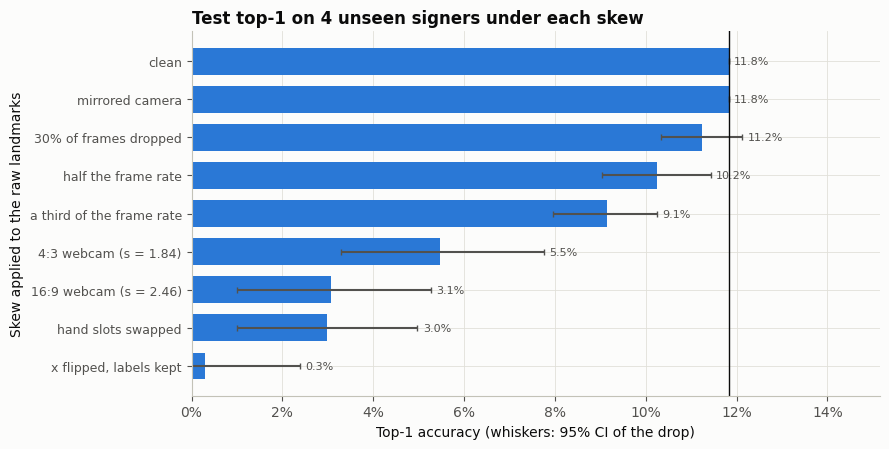

Takeaway: 'x flipped, labels kept' costs the most, 11.5 points (from 11.8% to 0.3%), while the mirrored camera costs 0.0 and half the frame rate 1.6.

In [14]:
from matplotlib.ticker import PercentFormatter

order = summary.sort_values("top1")
errors = np.vstack([order["ci_high"] - order["drop_pts"], order["drop_pts"] - order["ci_low"]]) / 100  # Left, right.


def skew_bars(ax, fontsize=8):
    """Top-1 per skew as bars, whiskers for the drop's 95% CI, each value written past its whisker."""
    y = np.arange(len(order))
    right = order["top1"].to_numpy() + errors[1]
    ax.barh(y, order["top1"], color=BLUE, height=0.7, xerr=errors, ecolor=INK_2, capsize=2)
    ax.axvline(results["clean"]["top1"], color=INK, linewidth=1)
    for yi, value, end in zip(y, order["top1"], right):
        ax.annotate(f"{value:.1%}", (end, yi), xytext=(4, 0), textcoords="offset points", va="center", color=INK_2,
                    fontsize=fontsize)
    ax.set_yticks(y, order.index, fontsize=fontsize + 1)
    ax.set_xlim(0, min(1.0, 1.25 * right.max()))
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))


fig, ax = plt.subplots(figsize=(9, 4.6))
skew_bars(ax)
ax.set(title="Test top-1 on 4 unseen signers under each skew", xlabel="Top-1 accuracy (whiskers: 95% CI of the drop)",
       ylabel="Skew applied to the raw landmarks")
plt.tight_layout()
plt.show()
worst = summary.drop("clean")["drop_pts"].idxmax()
takeaway(f"'{worst}' costs the most, {pts(summary.loc[worst, 'drop_pts'])} points (from {results['clean']['top1']:.1%} to "
         f"{summary.loc[worst, 'top1']:.1%}), while the mirrored camera costs {pts(summary.loc['mirrored camera', 'drop_pts'])} "
         f"and half the frame rate {pts(summary.loc['half the frame rate', 'drop_pts'])}.")

Preprocessing canonicalises handedness: a mirrored right-handed signer looks left-dominant, and preprocessing mirrors the sequence back. The exception is a tie, where both hands are visible in the same number of frames. The tie rule keeps such a sequence as it is, so with a mirrored camera it reaches the model as a mirror image. The next cell splits the mirrored-camera result by that rule.

In [15]:
def is_tie(xy):
    """Both hands visible in equally many frames (frames with no hand ignored)."""
    present = hand_presence(xy)
    present = present[present.any(axis=1)]
    return bool(present[:, 0].sum() == present[:, 1].sum())


tie = np.array([is_tie(xy) for xy in test_raw])
left_dominant = np.array([hand_presence(xy)[:, 0].sum() > hand_presence(xy)[:, 1].sum() for xy in test_raw])
by_test_signer = pd.Series(left_dominant[base]).groupby(test_rows.loc[base, "participant_id"].to_numpy()).mean()
print("left-dominant share per test signer:", by_test_signer.round(3).to_dict())
groups = {"both hands in equally many frames": base & tie, "one hand in more frames": base & ~tie}
display(pd.DataFrame({
    "sequences": [int(m.sum()) for m in groups.values()],
    "clean top-1": [rate(clean_correct, m) for m in groups.values()],
    "mirrored camera top-1": [rate(corrects["mirror"], m) for m in groups.values()],
}, index=list(groups)).round(3))
if (base & tie).any():
    takeaway(f"{tie[base].mean():.0%} of test sequences are ties; on them the mirrored camera scores "
             f"{rate(corrects['mirror'], base & tie):.1%} against {rate(clean_correct, base & tie):.1%} clean, and on the rest "
             f"{rate(corrects['mirror'], base & ~tie):.1%} against {rate(clean_correct, base & ~tie):.1%}.")
else:
    takeaway("No test sequence is a tie, so preprocessing mirrors every mirrored-camera sequence back.")

left-dominant share per test signer: {30680: 0.0, 37779: 0.0, 49445: 0.003, 62590: 0.007}


,sequences,clean top-1,mirrored camera top-1
both hands in equally many frames,0,NaN,NaN
one hand in more frames,1006,0.118,0.118


Takeaway: No test sequence is a tie, so preprocessing mirrors every mirrored-camera sequence back.

Swapping the hand slots is a different fault: the hands land in the wrong blocks relative to the body, and no later step can tell.

The intervals come from a paired bootstrap over sequences. Sequences from one signer are not independent, and with four test signers the per-signer range in the table above is the more honest view of the spread.

## 5. Fixing the hand slots

Holistic, which produced the training data, crops each hand from the pose, so its left-hand block is the hand at the pose's left wrist. A live pipeline can follow the same rule: give each detected hand to the block of the nearer pose wrist, and when both hands are seen, take the pairing with the smaller total distance. That is the fix ManuVox shipped.

,as tracked,after nearest-wrist assignment
correct slots,0.118,0.118
slots swapped,0.030,0.118


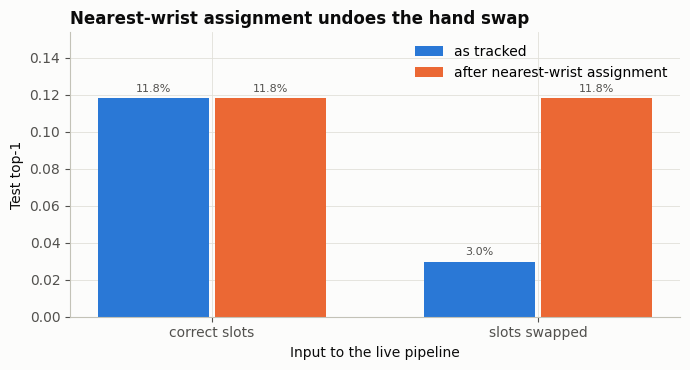

Takeaway: With swapped slots, assigning hands by the nearer pose wrist brings top-1 from 3.0% back to 11.8%; on correctly labelled data it changes top-1 by 0.0 points.

In [16]:
def assign_by_wrist(xy, i=0):
    """Reassign hands to blocks by distance to the pose wrists (Holistic's rule).

    Two hands: keep or swap, whichever pairing is closer in total. One hand: the block of the
    nearer wrist. Frames without both pose wrists keep their blocks.
    """
    out = xy.copy()
    lw, rw = xy[:, L_WRIST], xy[:, R_WRIST]
    hand_l, hand_r = xy[:, LEFT.start], xy[:, RIGHT.start]  # Hand wrists (hand point 0).
    dist = lambda a, b: np.hypot(*(a - b).T)  # noqa: E731
    has_l, has_r = np.isfinite(hand_l).all(1), np.isfinite(hand_r).all(1)
    pose_ok = np.isfinite(lw).all(1) & np.isfinite(rw).all(1)
    keep_cost = np.where(has_l, dist(hand_l, lw), 0) + np.where(has_r, dist(hand_r, rw), 0)
    swap_cost = np.where(has_l, dist(hand_l, rw), 0) + np.where(has_r, dist(hand_r, lw), 0)
    swap = pose_ok & (has_l | has_r) & (swap_cost < keep_cost)
    out[swap] = swap_hand_slots(xy[swap])
    return out


VARIANTS["clean_fixed"] = assign_by_wrist
VARIANTS["swap_fixed"] = lambda xy, i: assign_by_wrist(swap_hand_slots(xy))
clean_fixed, _ = run_variant("clean_fixed")
swap_fixed, _ = run_variant("swap_fixed")
fix = pd.DataFrame(
    {"as tracked": [clean_correct[base].mean(), swap_correct[base].mean()],
     "after nearest-wrist assignment": [clean_fixed[base].mean(), swap_fixed[base].mean()]},
    index=["correct slots", "slots swapped"],
)
display(fix.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(2)
for j, (column, colour) in enumerate(zip(fix.columns, (BLUE, ORANGE))):
    bars = ax.bar(x + (j - 0.5) * 0.36, fix[column], width=0.34, color=colour, label=column)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in fix[column]], padding=3, color=INK_2, fontsize=8)
ax.set_xticks(x, fix.index)
ax.set(title="Nearest-wrist assignment undoes the hand swap", xlabel="Input to the live pipeline",
       ylabel="Test top-1", ylim=(0, min(1.0, 1.3 * fix.values.max())))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
takeaway(f"With swapped slots, assigning hands by the nearer pose wrist brings top-1 from {swap_correct[base].mean():.1%} back to "
         f"{swap_fixed[base].mean():.1%}; on correctly labelled data it changes top-1 by {pts(100 * (clean_fixed[base].mean() - clean_correct[base].mean()), signed=True)} points.")

## 6. Aspect ratio: a sweep and a self-calibrating fix

If the app knows the frame's width and height, it can undo the stretch exactly: scale y by k = 0.723 / (width / height). ManuVox does this. When the frame size is unreliable, a pipeline can calibrate from the body instead: measure the body ratio r (nose height over shoulder width, see notebook 1) and scale y so that r matches the training median. The sweep below compares no correction with that body-based correction, which also removes the natural spread of r between people.

In [17]:
def body_ratio(xy):
    """Median r = |nose y - shoulder-midpoint y| / |shoulder x distance| over frames with a hand and all three points."""
    nose, ls, rs = xy[:, NOSE], xy[:, L_SHOULDER], xy[:, R_SHOULDER]
    width = np.abs(ls[:, 0] - rs[:, 0])
    with np.errstate(invalid="ignore", divide="ignore"):
        r = np.abs(nose[:, 1] - 0.5 * (ls[:, 1] + rs[:, 1])) / width
    r = r[np.isfinite(r) & (width > 0) & hand_presence(xy).any(axis=1)]  # Kept frames, as in training.
    return float(np.median(r)) if len(r) else np.nan


def train_body_ratio(X):
    """The training median of r, read from preprocessed frames (r survives centring, scaling and mirroring)."""
    pts = X[..., : 2 * N_LANDMARKS].astype(np.float32).reshape(-1, N_LANDMARKS, 2)
    nose, ls, rs = pts[:, NOSE], pts[:, L_SHOULDER], pts[:, R_SHOULDER]
    ok = (np.abs(nose).sum(1) > 0) & (np.abs(ls).sum(1) > 0) & (np.abs(rs).sum(1) > 0) & (ls[:, 0] != rs[:, 0])
    return float(np.median(np.abs(nose[ok, 1] - 0.5 * (ls[ok, 1] + rs[ok, 1])) / np.abs(ls[ok, 0] - rs[ok, 0])))


R_TRAIN = train_body_ratio(X_fit[train_mask])
print(f"training median body ratio r = {R_TRAIN:.3f}")


def calibrate_aspect(xy, i=0):
    """Scale y about 0.5 so the sequence's body ratio equals the training median (k clamped to 0.25-4)."""
    r = body_ratio(xy)
    return xy if not np.isfinite(r) or r == 0 else stretch_y(xy, float(np.clip(R_TRAIN / r, 0.25, 4.0)))

training median body ratio r = 0.396


s,0.50,0.75,1.00,1.25,1.50,1.84,2.00,2.46,3.00
no correction,0.059,0.096,0.118,0.114,0.083,0.056,0.040,0.030,0.025
body-ratio correction,0.131,0.131,0.131,0.131,0.131,0.131,0.131,0.131,0.131


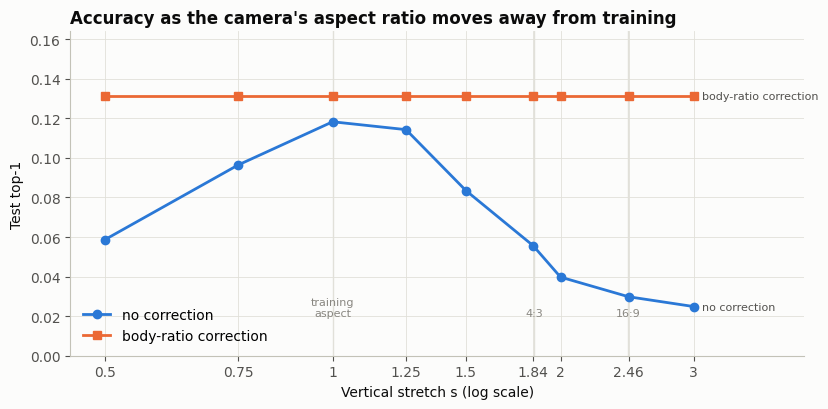

Takeaway: Without correction, a 16:9 webcam (s = 2.46) gives 3.0% against 11.8% at the training aspect; with the body-ratio correction top-1 is 13.1% across the whole sweep, and the correction changes top-1 by +1.3 points when nothing is wrong.

In [18]:
STRETCHES = [0.5, 0.75, 1.0, 1.25, 1.5, 1.84, 2.0, 2.46, 3.0]
sweep = []
for s in STRETCHES:
    VARIANTS[f"s{s}"] = lambda xy, i, s=s: stretch_y(xy, s)
    VARIANTS[f"s{s}_cal"] = lambda xy, i, s=s: calibrate_aspect(stretch_y(xy, s))
    sweep.append({"s": s, "no correction": run_variant(f"s{s}")[0][base].mean(),
                  "body-ratio correction": run_variant(f"s{s}_cal")[0][base].mean()})
sweep = pd.DataFrame(sweep).set_index("s")
display(sweep.round(3).T)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for column, colour, marker in (("no correction", BLUE, "o"), ("body-ratio correction", ORANGE, "s")):
    ax.plot(sweep.index, sweep[column], color=colour, marker=marker, markersize=6, linewidth=2, label=column)
    ax.annotate(column, (sweep.index[-1], sweep[column].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color=INK_2, fontsize=8, va="center")
for s, name in ((1.0, "training\naspect"), ((4 / 3) / TRAIN_WIDTH_OVER_HEIGHT, "4:3"), ((16 / 9) / TRAIN_WIDTH_OVER_HEIGHT, "16:9")):
    ax.axvline(s, color=GRID, linewidth=1, zorder=0)
    ax.annotate(name, (s, 0.02), ha="center", color=MUTED, fontsize=8)
ax.set_xscale("log")
ax.set_xticks(STRETCHES, [f"{s:g}" for s in STRETCHES])
ax.minorticks_off()
ax.set(title="Accuracy as the camera's aspect ratio moves away from training", xlabel="Vertical stretch s (log scale)",
       ylabel="Test top-1", ylim=(0, min(1.0, 1.25 * sweep.values.max())), xlim=(0.45, 4.2))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
def span(values):
    """'a% to b%' for a range of accuracies, or a single 'a%' when every value rounds the same."""
    low, high = f"{values.min():.1%}", f"{values.max():.1%}"
    return low if low == high else f"{low} to {high}"


takeaway(f"Without correction, a 16:9 webcam (s = 2.46) gives {sweep.loc[2.46, 'no correction']:.1%} against "
         f"{sweep.loc[1.0, 'no correction']:.1%} at the training aspect; with the body-ratio correction top-1 is "
         f"{span(sweep['body-ratio correction'])} across the whole sweep, and the correction changes "
         f"top-1 by {pts(100 * (sweep.loc[1.0, 'body-ratio correction'] - sweep.loc[1.0, 'no correction']), signed=True)} points "
         "when nothing is wrong.")

## 7. Frame rate and dropped frames

Training resamples every sequence to 32 frames by frame index, so a lower but steady frame rate mostly changes how many real frames feed the interpolation. Random drops are different: they warp time, because the index no longer advances at a steady pace. The plot compares the two at the same share of frames kept.

,steady lower rate,random drops,no prediction (steady),no prediction (random)
share kept,,,,
1.000000,0.118,0.118,0,0
0.500000,0.102,0.095,139,156
0.333333,0.091,0.086,206,298
0.250000,0.080,0.058,296,409
0.166667,0.058,0.041,488,584


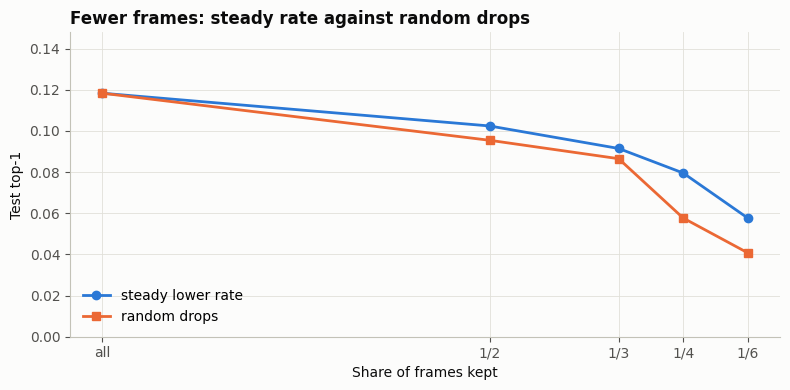

Takeaway: Keeping a steady 1/3 of the frames gives 9.1% and dropping 2/3 at random 8.6%, against 11.8% with every frame; at 1/6, 488 sequences no longer have 3 hand frames.

In [19]:
frame_rows = []
for k in (1, 2, 3, 4, 6):
    share = 1 / k
    VARIANTS[f"every{k}"] = lambda xy, i, k=k: keep_every(xy, k)
    VARIANTS[f"drop{k}"] = lambda xy, i, k=k: drop_random(xy, 1 - 1 / k, i)
    steady, steady_kept = run_variant(f"every{k}")
    random_, random_kept = run_variant(f"drop{k}")
    frame_rows.append({"share kept": share, "steady lower rate": steady[base].mean(), "random drops": random_[base].mean(),
                       "no prediction (steady)": int((base & ~steady_kept).sum()),
                       "no prediction (random)": int((base & ~random_kept).sum())})
frames_df = pd.DataFrame(frame_rows).set_index("share kept")
display(frames_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for column, colour, marker in (("steady lower rate", BLUE, "o"), ("random drops", ORANGE, "s")):
    ax.plot(frames_df.index, frames_df[column], color=colour, marker=marker, markersize=6, linewidth=2, label=column)
ax.invert_xaxis()
ax.set_xticks(frames_df.index, ["all", "1/2", "1/3", "1/4", "1/6"])
ax.set(title="Fewer frames: steady rate against random drops", xlabel="Share of frames kept",
       ylabel="Test top-1", ylim=(0, min(1.0, 1.25 * frames_df[["steady lower rate", "random drops"]].values.max())))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
takeaway(f"Keeping a steady 1/3 of the frames gives {frames_df.loc[1 / 3, 'steady lower rate']:.1%} and dropping 2/3 at random "
         f"{frames_df.loc[1 / 3, 'random drops']:.1%}, against {frames_df.loc[1.0, 'steady lower rate']:.1%} with every frame; at 1/6, "
         f"{frames_df.loc[1 / 6, 'no prediction (steady)']} sequences no longer have 3 hand frames.")

The cover image of this notebook is the summary bar chart from section 4, redrawn at 1280x720.

In [20]:
fig, ax = plt.subplots(figsize=(12.8, 7.2))
skew_bars(ax, fontsize=12)
ax.set_xlabel("Test top-1 on 4 unseen signers (whiskers: 95% CI of the drop)", fontsize=12)
ax.set_title(f"Train-serve skew in a MediaPipe sign classifier\n'{worst}' costs the most: "
             f"{results['clean']['top1']:.1%} falls to {summary.loc[worst, 'top1']:.1%}", fontsize=16, pad=14)
plt.tight_layout()
save_cover(fig)
plt.close(fig)

## 8. What we found

In [21]:
display(Markdown(
    f"On four signers the model never saw, the clean pipeline scores {results['clean']['top1']:.1%} top-1, swapping the hand "
    f"slots (the ManuVox bug) drops it to {summary.loc['hand slots swapped', 'top1']:.1%}, and assigning hands by the nearer "
    f"pose wrist brings it back to {swap_fixed[base].mean():.1%}. "
    f"A mirrored camera costs {pts(summary.loc['mirrored camera', 'drop_pts'])} points because preprocessing mirrors left-dominant "
    + (f"input back; on the {tie[base].mean():.0%} of sequences where both hands are visible equally often it scores "
       f"{rate(corrects['mirror'], base & tie):.1%} against {rate(clean_correct, base & tie):.1%} clean. "
       if (base & tie).any() else "input back, and no test sequence is a tie. ")
    + f"Flipping x without relabelling costs {pts(summary.loc['x flipped, labels kept', 'drop_pts'])} points and a 16:9 webcam "
    f"without aspect correction {pts(summary.loc['16:9 webcam (s = 2.46)', 'drop_pts'])}. "
    f"With the body-ratio correction, top-1 is {span(sweep['body-ratio correction'])} at every stretch in the sweep. "
    f"Halving the frame rate changes top-1 by {pts(-summary.loc['half the frame rate', 'drop_pts'], signed=True)} points and "
    f"dropping 30% of frames at random by {pts(-summary.loc['30% of frames dropped', 'drop_pts'], signed=True)}."
))

On four signers the model never saw, the clean pipeline scores 11.8% top-1, swapping the hand slots (the ManuVox bug) drops it to 3.0%, and assigning hands by the nearer pose wrist brings it back to 11.8%. A mirrored camera costs 0.0 points because preprocessing mirrors left-dominant input back, and no test sequence is a tie. Flipping x without relabelling costs 11.5 points and a 16:9 webcam without aspect correction 8.7. With the body-ratio correction, top-1 is 13.1% at every stretch in the sweep. Halving the frame rate changes top-1 by -1.6 points and dropping 30% of frames at random by -0.6.

### Limitations

- These are simulations on recorded landmarks. A live tracker also adds noise, misses hands and segments signs, none of which is modelled here. The repository's live-gap study measures those on real webcam clips.
- The model trains for 30 epochs against notebook 4's 80; every drop is measured against this model's own clean score.
- Four test signers is a small sample, and all four are right-dominant in this split (section 4 prints the left-dominant share per signer).
- The aspect stretch assumes the training videos' effective width-to-height ratio of 0.723 estimated in the repository; if it is off, the s values for 4:3 and 16:9 shift.

### Ideas to try

- Train with aspect and frame-rate augmentation and rerun the sweeps to see how much of each gap training can close.
- Add tracker-style hand dropout (random frames where one hand disappears) and measure it the same way.
- Swap the hands in only some frames, as a flickering handedness label would, instead of all of them.

### The series

- [1. ASL Signs EDA: animating 94k landmark sequences](https://www.kaggle.com/code/swapnilshukla007/asl-signs-eda-animating-94k-landmark-sequences)
- [3. Why random splits overstate sign recognition accuracy](https://www.kaggle.com/code/swapnilshukla007/why-random-splits-overstate-sign-accuracy)
- [4. A CNN + Transformer hybrid for isolated sign recognition in PyTorch](https://www.kaggle.com/code/swapnilshukla007/cnn-transformer-hybrid-for-isolated-asl-signs)
- [5. From PyTorch to the browser: ONNX export, FP16/INT8 quantization and temperature calibration](https://www.kaggle.com/code/swapnilshukla007/pytorch-to-browser-onnx-fp16-int8-calibration)

If this helped, an upvote helps other people find it, and feedback in the comments is welcome.